# Bayesian inference and parameter uncertainty

Generated observations show how beliefs about parameters change with data, and
why future observations remain uncertain even when parameters become precise.
These exact conjugate examples use the standard dependencies. The [catalog](../bayesian_inference.md)
and [PyMC example](../examples/bayesian_pymc.py) cover MCMC, ADVI and joint inference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from convexity.math import bayesian as b, distributions as dist
rng = np.random.default_rng(110)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})

## Learning a probability

Each update uses additional Bernoulli observations. The posterior contracts
around the generated probability; the prior remains a separate immutable object.

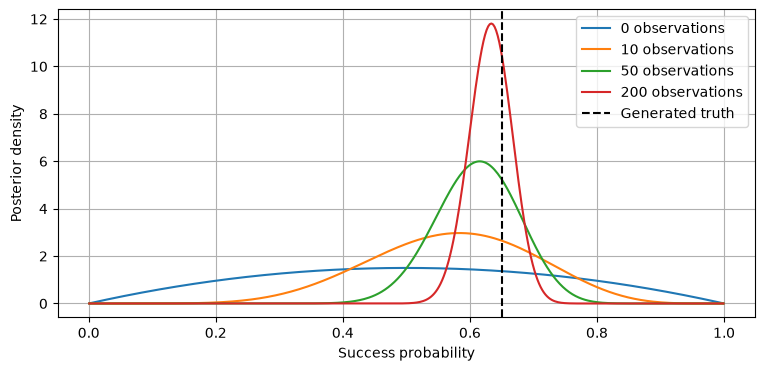

In [2]:
truth = .65
observed = rng.binomial(1, truth, 200)
prior = b.BetaBinomial(2, 2)
grid = np.linspace(.001, .999, 400)
fig, ax = plt.subplots()
for count in [0, 10, 50, 200]:
    posterior = prior.update(observed[:count])
    ax.plot(grid, posterior.posterior.density(grid), label=f'{count} observations')
ax.axvline(truth, color='black', linestyle='--', label='Generated truth')
ax.set(xlabel='Success probability', ylabel='Posterior density')
ax.legend()
plt.show()

## Parameter uncertainty and predictive uncertainty

The mean parameter becomes more precise with additional observations. Future
observations still include their own noise. The predictive variance is the sum
of parameter variance and known observation variance.

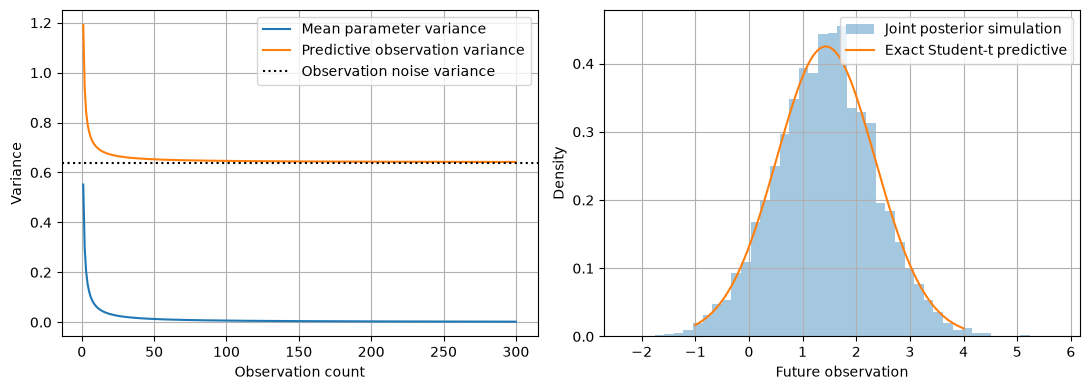

In [3]:
observations = rng.normal(1.5, .8, 300)
prior_mean = b.NormalMean(0, 4, .8**2)
counts = np.arange(1, 301)
parameter_variance = np.array([prior_mean.update(observations[:n]).variance for n in counts])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(counts, parameter_variance, label='Mean parameter variance')
axes[0].plot(counts, parameter_variance + .8**2, label='Predictive observation variance')
axes[0].axhline(.8**2, color='black', linestyle=':', label='Observation noise variance')
axes[0].set(xlabel='Observation count', ylabel='Variance')
axes[0].legend()
posterior = b.NormalInverseGamma().update(observations[:40])
predictive = b.posterior_predictive(posterior.posterior,
    lambda theta: dist.normal(theta[0], np.sqrt(theta[1])), draws=6000, rng=rng)
generated = predictive.sample(6000, rng=rng)
axes[1].hist(generated, bins=45, density=True, alpha=.4, label='Joint posterior simulation')
grid = np.linspace(-1, 4, 300)
axes[1].plot(grid, posterior.predictive().density(grid), label='Exact Student-t predictive')
axes[1].set(xlabel='Future observation', ylabel='Density')
axes[1].legend()
plt.tight_layout()
plt.show()

## Shared coefficient uncertainty

Future regression means share the same uncertain coefficients. Curves below
are joint draws, so the covariance between locations is preserved. The shaded
interval includes observation noise and is pointwise, not a simultaneous band.

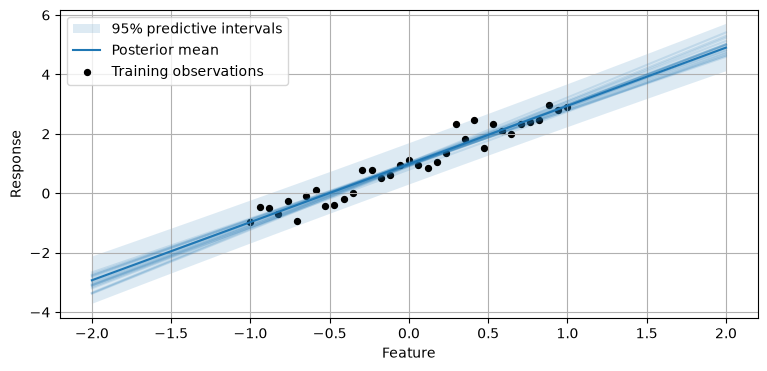

Posterior coefficients: [0.98626336 1.95765838]
Coefficient covariance:
 [[3.49694018e-03 4.38915319e-19]
 [4.38915319e-19 9.89214240e-03]]


In [4]:
training = np.linspace(-1, 1, 35)
x = np.column_stack([np.ones(len(training)), training])
y = x @ np.array([1., 2.]) + rng.normal(0, .35, len(x))
regression = b.GaussianLinearRegression([0, 0], 4*np.eye(2), .35**2).update(x, y)
query = np.linspace(-2, 2, 100)
design = np.column_stack([np.ones(len(query)), query])
mean = design @ regression.mean
latent_variance = np.einsum('ij,jk,ik->i', design, regression.covariance, design)
coefficient_draws = regression.posterior.sample(20, rng=rng)
fig, ax = plt.subplots()
ax.plot(query, design @ coefficient_draws.T, color='C0', alpha=.15)
ax.fill_between(query, mean-1.96*np.sqrt(latent_variance+.35**2),
                mean+1.96*np.sqrt(latent_variance+.35**2), alpha=.15, label='95% predictive intervals')
ax.plot(query, mean, color='C0', label='Posterior mean')
ax.scatter(training, y, color='black', s=18, label='Training observations')
ax.set(xlabel='Feature', ylabel='Response')
ax.legend()
plt.show()
print('Posterior coefficients:', regression.mean)
print('Coefficient covariance:\n', regression.covariance)

Conjugacy gives exact answers under these specified Gaussian and count models.
The test suite checks the identities and compares library inference with known
posteriors. For nonconjugate models, inspect MCMC diagnostics or variational
approximation quality rather than treating a completed fit as proof of accuracy.